# RISK ANALYTICS — 06 Pérdidas Agregadas y VaR

**Alcance:** estimación de la distribución de pérdidas agregadas de riesgo operacional por simulación Monte Carlo (método LDA — Loss Distribution Approach), a partir de los modelos de frecuencia y severidad aprobados en el notebook 06 y persistidos en `eventosriesgoyvar.gold.ajustes_modelos` (filas con `resultado = 'SELECCIONADA'`, sin hardcodear parámetros):
* **Frecuencia mensual (solo eventos A):** Binomial Negativa — r = 8,3288, p = 0,3639 (media mensual 14,56; 142 meses, dic-2014 a sep-2026).
* **Severidad (pérdidas A, cuantía bruta):** Lognormal — μ = 11,9473, σ = 2,3265 (n = 2.046).

**Fuera de alcance (no construidos aquí):** dashboard, modelos EVT/GPD para la cola extrema, segmentación por categoría de riesgo.

## Documentación del cálculo

| Elemento | Valor |
| --- | --- |
| Método | Monte Carlo LDA (frecuencia × severidad compuesta) |
| Horizonte | MENSUAL (1 mes) y ANUAL (12 meses independientes) |
| Nivel de confianza | 95 % y 99 % (99,9 % solo como referencia de cola) |
| Número de simulaciones | 100.000 escenarios por horizonte (y por escenario de sensibilidad) |
| Semilla | 20261122 — fija y única para todos los escenarios, de modo que las diferencias entre escenarios sean paramétricas y no ruido de Monte Carlo |
| Distribución de frecuencia | Binomial Negativa (BN) con r y p leídos de `gold.ajustes_modelos` |
| Distribución de severidad | Lognormal con μ y σ leídos de `gold.ajustes_modelos` |
| Moneda | COP — cuantía bruta |
| Tratamiento de recuperaciones | NO modeladas: solo 235 de 51.889 eventos tienen recuperación; se estima la pérdida BRUTA |
| Fecha de corte de la información | 2026-09-30 (último mes con eventos: septiembre de 2026) |

**Estructura del notebook:** (1) simulación de pérdidas agregadas; (2) distribución simulada; (3) pérdida esperada; (4) VaR 95/99/99,9; (5) gráficos; (6) escenarios y sensibilidad; (7) backtesting con los 142 meses históricos; (8) persistencia en tablas Delta de Gold para el dashboard; limitaciones y registro de decisiones.

## Metodología

**Simulación Monte Carlo LDA.** Para cada escenario *i* se genera el número de eventos del mes N<sub>i</sub> ~ BinomialNegativa(r, p) y, para cada evento, su severidad X<sub>ij</sub> ~ Lognormal(μ, σ); la pérdida agregada es L<sub>i</sub> = Σ<sub>j</sub> X<sub>ij</sub>. El horizonte anual es la suma de 12 meses independientes con la misma mecánica. La implementación es vectorizada con `numpy` (generador `default_rng(semilla)`), lo que permite 100.000 escenarios por horizonte en segundos y garantiza reproducibilidad exacta.

**Métricas.**
* **Pérdida Esperada (EL):** promedio de las pérdidas simuladas — coincide, salvo error de Monte Carlo, con el valor teórico E[N]·E[X] = 14,56 × exp(μ + σ²/2).
* **VaR<sub>q</sub>:** percentil q de la distribución simulada (95 %, 99 %; 99,9 % de referencia).
* **CVaR<sub>q</sub> (Expected Shortfall):** promedio de las pérdidas que exceden el VaR<sub>q</sub> — mide la severidad de la pérdida *cuando* se excede el VaR.

**Validación interna.** EL simulado debe quedar a menos de 2 % del EL teórico mensual (33,65 millones COP); si se desvía, se aumenta el número de simulaciones.

**Sensibilidad.** Se re-simula el horizonte mensual moviendo un parámetro a la vez (media de frecuencia ±10 %, μ +5 %, σ +10 %) y un escenario estresado combinado, con la misma semilla: las diferencias entre escenarios reflejan solo el cambio paramétrico.

**Backtesting.** Se compara el VaR mensual modelo contra la pérdida mensual agregada histórica de los eventos A con cuantía (142 meses, meses sin pérdida = 0). El test de Kupiec (proporción de fallas) contrasta la tasa de excedencias observada contra la esperada (5 % y 1 %): LR = −2·ln(L₀/L₁) ~ χ²(1), con L₀ = (1−α)ⁿ⁻ˣ·αˣ y L₁ evaluada en p̂ = x/n.

**Advertencia central:** el VaR es un percentil de la distribución MODELADA, no una pérdida máxima absoluta (ver la sección dedicada).

In [0]:
import numpy as np
import pandas as pd
from scipy import stats
from datetime import datetime, date
from pyspark.sql import functions as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

CATALOGO = "eventosriesgoyvar"
SCHEMA_GOLD = f"{CATALOGO}.gold"
DIR_GRAFICOS = "/Volumes/eventosriesgoyvar/default/bdeventos/analisis_graficos"
LOTE_VAR = f"var_{datetime.now().strftime('%Y%m%d_%H%M%S')}"

# --- Documentación del cálculo (valores fijos del proceso) ---
SEMILLA = 20261122          # semilla única para TODOS los escenarios
N_SIM = 100_000             # simulaciones por horizonte y por escenario
HORIZONTES = {"MENSUAL": 1, "ANUAL": 12}
MONEDA = "COP (cuantía bruta; recuperaciones NO modeladas)"
FECHA_CORTE = "2026-09-30"
FECHA_CALCULO = datetime.now().date()

# --- Parámetros aprobados: leídos de gold.ajustes_modelos (SELECCIONADA), no hardcodeados ---
aj = spark.table(f"{SCHEMA_GOLD}.ajustes_modelos").toPandas()
bn = aj[(aj.serie == "FRECUENCIA_A") & (aj.distribucion == "BINOMIAL_NEGATIVA") & (aj.resultado == "SELECCIONADA")].iloc[0]
ln = aj[(aj.serie == "SEVERIDAD_A") & (aj.distribucion == "LOGNORMAL") & (aj.resultado == "SELECCIONADA")].iloc[0]
r, p = float(bn.param1_valor), float(bn.param2_valor)      # BN: r (tamaño), p (éxito)
mu, sigma = float(ln.param1_valor), float(ln.param2_valor)  # Lognormal: mu, sigma (escala ln COP)

MEDIA_N = r * (1 - p) / p                    # media mensual de eventos (teórica BN)
E_X = float(np.exp(mu + sigma**2 / 2))       # media de severidad (teórica lognormal)
EL_TEORICO = MEDIA_N * E_X                    # pérdida esperada mensual teórica

# Verificación: los parámetros leídos deben ser los aprobados en el notebook 06
assert str(bn.param1_nombre).startswith("r") and str(bn.param2_nombre) == "p", "Nombres de parámetros BN inesperados"
assert str(ln.param1_nombre).startswith("mu") and str(ln.param2_nombre) == "sigma", "Nombres de parámetros lognormal inesperados"
assert abs(MEDIA_N - 14.56) < 0.01, f"Media BN leída = {MEDIA_N:.4f} (se esperaba ~14,56)"
assert abs(mu - 11.9473) < 5e-4 and abs(sigma - 2.3265) < 5e-4, "Parámetros lognormal no coinciden con los aprobados"

print(f"=== PARÁMETROS APROBADOS (gold.ajustes_modelos, lote {bn['_lote_analisis']}) ===\n")
print(f"Frecuencia  BN     : r = {r:.4f}, p = {p:.4f}  ->  media mensual = {MEDIA_N:.2f} eventos")
print(f"Severidad   Lognorm: mu = {mu:.4f}, sigma = {sigma:.4f}  ->  media severidad = {E_X:,.0f} COP")
print(f"EL teórico mensual : E[N]·E[X] = {EL_TEORICO:,.0f} COP")
print(f"\nSemilla = {SEMILLA} | n_sim = {N_SIM:,} por horizonte | Moneda: {MONEDA} | Corte: {FECHA_CORTE}")
print(f"Horizontes: {', '.join(f'{h} ({m} mes(es))' for h, m in HORIZONTES.items())} | Lote: {LOTE_VAR}")

=== PARÁMETROS APROBADOS (gold.ajustes_modelos, lote analisis_20261121_221926) ===

Frecuencia  BN     : r = 8.3288, p = 0.3639  ->  media mensual = 14.56 eventos
Severidad   Lognorm: mu = 11.9473, sigma = 2.3265  ->  media severidad = 2,311,632 COP
EL teórico mensual : E[N]·E[X] = 33,648,892 COP

Semilla = 20261122 | n_sim = 100,000 por horizonte | Moneda: COP (cuantía bruta; recuperaciones NO modeladas) | Corte: 2026-09-30
Horizontes: MENSUAL (1 mes(es)), ANUAL (12 mes(es)) | Lote: var_20261121_224527


## 1–3. Simulación de pérdidas agregadas, distribución y pérdida esperada

Cada escenario mensual simula: (i) cuántos eventos A ocurren (N ~ BN) y (ii) la severidad bruta de cada uno (X ~ Lognormal); la pérdida agregada del escenario es la suma de sus severidades. Con 100.000 escenarios se obtiene la distribución empírica simulada de la pérdida agregada mensual, y sumando 12 meses independientes, la anual.

La **pérdida esperada** es el promedio de las pérdidas simuladas. Como control de calidad, debe reproducir el valor teórico E[N]·E[X] con desviación < 2 %; en caso contrario se aumenta el número de simulaciones.

In [0]:
def simular_perdida_agregada(r, p, mu, sigma, n_sim, n_meses=1, semilla=SEMILLA):
    """Simula n_sim escenarios de pérdida agregada a n_meses meses (independientes).

    N ~ BinomialNegativa(r, p) eventos por mes; X ~ Lognormal(mu, sigma) COP;
    L = suma de las severidades de cada escenario. Vectorizado y reproducible.
    """
    rng = np.random.default_rng(semilla)
    N = rng.negative_binomial(r, p, size=n_sim * n_meses)
    if N.sum() == 0:
        return np.zeros(n_sim)
    sev = rng.lognormal(mu, sigma, size=int(N.sum()))
    esc = np.repeat(np.arange(n_sim * n_meses), N)
    tot = np.bincount(esc, weights=sev, minlength=n_sim * n_meses)
    return tot.reshape(n_sim, n_meses).sum(axis=1)

def metricas(L):
    """EL, VaR 95/99/99,9 y CVaR 95/99 de un vector de pérdidas simuladas."""
    v95, v99 = np.percentile(L, 95), np.percentile(L, 99)
    return dict(EL=float(L.mean()), VaR95=float(v95), VaR99=float(v99),
                VaR999=float(np.percentile(L, 99.9)),
                CVaR95=float(L[L >= v95].mean()), CVaR99=float(L[L >= v99].mean()))

# --- Validación interna: EL simulado vs EL teórico mensual ---
L_val = simular_perdida_agregada(r, p, mu, sigma, N_SIM, 1)
ratio_el = L_val.mean() / EL_TEORICO
print(f"=== VALIDACIÓN INTERNA (MENSUAL, {N_SIM:,} simulaciones, semilla {SEMILLA}) ===")
print(f"EL teórico  = E[N]·E[X] = {MEDIA_N:.2f} × {E_X:,.0f} = {EL_TEORICO:,.0f} COP")
print(f"EL simulado = {L_val.mean():,.0f} COP  ->  ratio = {ratio_el:.4f}")
assert 0.98 < ratio_el < 1.02, (
    f"EL simulado se desvía {abs(ratio_el-1):.1%} del teórico: aumentar n_sim y repetir."
)
print("OK: desviación < 2 % del teórico — el número de simulaciones es suficiente para la EL.")

=== VALIDACIÓN INTERNA (MENSUAL, 100,000 simulaciones, semilla 20261122) ===
EL teórico  = E[N]·E[X] = 14.56 × 2,311,632 = 33,648,892 COP
EL simulado = 33,860,377 COP  ->  ratio = 1.0063
OK: desviación < 2 % del teórico — el número de simulaciones es suficiente para la EL.


In [0]:
# --- Simulación base: horizonte mensual y anual ---
L_m = simular_perdida_agregada(r, p, mu, sigma, N_SIM, 1)   # 100.000 escenarios mensuales
L_a = simular_perdida_agregada(r, p, mu, sigma, N_SIM, 12)  # 100.000 escenarios anuales (12 meses)
MET_M, MET_A = metricas(L_m), metricas(L_a)

print(f"=== DISTRIBUCIÓN DE PÉRDIDA AGREGADA SIMULADA (BASE, {N_SIM:,} simulaciones, semilla {SEMILLA}) ===\n")
for nombre, met in [("HORIZONTE MENSUAL (1 mes)", MET_M), ("HORIZONTE ANUAL (12 meses)", MET_A)]:
    print(f"{nombre}")
    print(f"  Pérdida Esperada (EL)  : {met['EL']:>15,.0f} COP")
    print(f"  VaR 95 %               : {met['VaR95']:>15,.0f} COP")
    print(f"  VaR 99 %               : {met['VaR99']:>15,.0f} COP")
    print(f"  VaR 99,9 % (referencia): {met['VaR999']:>15,.0f} COP")
    print(f"  CVaR 95 %              : {met['CVaR95']:>15,.0f} COP")
    print(f"  CVaR 99 %              : {met['CVaR99']:>15,.0f} COP")
    print()
print(f"Eventos simulados: {N_SIM*12*14.56/12e6:.2f} millones de severidades en el horizonte anual")
print("El VaR 99,9 % excede por mucho al VaR 99 % — la cola derecha es muy pesada (Hill alpha = 0,864 < 1).")

=== DISTRIBUCIÓN DE PÉRDIDA AGREGADA SIMULADA (BASE, 100,000 simulaciones, semilla 20261122) ===

HORIZONTE MENSUAL (1 mes)
  Pérdida Esperada (EL)  :      33,860,377 COP
  VaR 95 %               :     110,628,842 COP
  VaR 99 %               :     297,062,242 COP
  VaR 99,9 % (referencia):   1,108,574,332 COP
  CVaR 95 %              :     269,547,046 COP
  CVaR 99 %              :     678,904,517 COP

HORIZONTE ANUAL (12 meses)
  Pérdida Esperada (EL)  :     404,157,653 COP
  VaR 95 %               :     856,434,100 COP
  VaR 99 %               :   1,666,749,828 COP
  VaR 99,9 % (referencia):   4,842,886,955 COP
  CVaR 95 %              :   1,471,201,567 COP
  CVaR 99 %              :   2,925,247,230 COP

Eventos simulados: 1.46 millones de severidades en el horizonte anual
El VaR 99,9 % excede por mucho al VaR 99 % — la cola derecha es muy pesada (Hill alpha = 0,864 < 1).


## 4. VaR 95 % y 99 % — y por qué NO representa una pérdida máxima absoluta

El VaR al 95 % (99 %) es el valor de pérdida que la distribución simulada excede solo con probabilidad del 5 % (1 %) **por periodo**. Consecuencias obligatorias de esa definición:

* **El VaR se excede, con certeza estadística.** En 20 meses típicos, uno excederá el VaR 95 %; en 100, uno excederá el VaR 99 %. Exceder el VaR no es una anomalía: es lo que la propia definición anticipa.
* **Cuando se excede, la pérdida puede ser mucho mayor que el VaR.** El CVaR 95 % mensual es ~2,4 veces el VaR 95 % mensual, y el VaR 99,9 % es ~3,7 veces el VaR 99 % — la cola derecha es muy pesada.
* **El máximo simulado supera con creces cualquier VaR reportado** (ver celda siguiente).
* **El VaR es un percentil de la distribución MODELADA, no de la realidad.** Está condicionado a los supuestos de los modelos subyacentes (BN + Lognormal ajustadas a datos con las limitaciones documentadas en el notebook 06: 48,5 % de eventos sin cuantía, rechazo leve de KS, cola extrema no confiable con α de Hill < 1). Un evento fuera del rango histórico modelado puede producir pérdidas superiores a cualquier VaR.

Por eso se reportan también el CVaR y el VaR 99,9 % de referencia, y por eso **el VaR no debe comunicarse como “la pérdida máxima posible”**.

In [0]:
print("=== EVIDENCIA NUMÉRICA: EL VaR NO ES UNA PÉRDIDA MÁXIMA ABSOLUTA ===\n")
print(f"1) Excedencias esperadas por periodo (frecuencia con que SE ESPERA superar el VaR):")
print(f"   VaR 95 (mensual o anual): se excede en ~{0.05*100:5.1f} % de los periodos (1 de cada 20)")
print(f"   VaR 99 (mensual o anual): se excede en ~{0.01*100:5.1f} % de los periodos (1 de cada 100)")
print(f"   Prob. de exceder el VaR 99 mensual al menos una vez en 12 meses: {1-0.99**12:.1%}")

print(f"\n2) Cuando se excede, la pérdida típica supera al VaR:")
print(f"   CVaR 95 / VaR 95 (mensual)  = {MET_M['CVaR95']/MET_M['VaR95']:.2f}x")
print(f"   CVaR 99 / VaR 99 (mensual)  = {MET_M['CVaR99']/MET_M['VaR99']:.2f}x")
print(f"   VaR 99,9 / VaR 99 (mensual) = {MET_M['VaR999']/MET_M['VaR99']:.2f}x")

print(f"\n3) El máximo de las simulaciones está muy por encima de todos los VaR:")
print(f"   Máximo simulado mensual  : {L_m.max():,.0f} COP  = {L_m.max()/MET_M['VaR99']:.1f}x el VaR 99")
print(f"   Máximo simulado anual    : {L_a.max():,.0f} COP  = {L_a.max()/MET_A['VaR99']:.1f}x el VaR 99 anual")
print(f"   Y ese máximo es solo el mayor de {N_SIM:,} escenarios: nada impide uno peor.")

=== EVIDENCIA NUMÉRICA: EL VaR NO ES UNA PÉRDIDA MÁXIMA ABSOLUTA ===

1) Excedencias esperadas por periodo (frecuencia con que SE ESPERA superar el VaR):
   VaR 95 (mensual o anual): se excede en ~  5.0 % de los periodos (1 de cada 20)
   VaR 99 (mensual o anual): se excede en ~  1.0 % de los periodos (1 de cada 100)
   Prob. de exceder el VaR 99 mensual al menos una vez en 12 meses: 11.4%

2) Cuando se excede, la pérdida típica supera al VaR:
   CVaR 95 / VaR 95 (mensual)  = 2.44x
   CVaR 99 / VaR 99 (mensual)  = 2.29x
   VaR 99,9 / VaR 99 (mensual) = 3.73x

3) El máximo de las simulaciones está muy por encima de todos los VaR:
   Máximo simulado mensual  : 11,124,122,295 COP  = 37.4x el VaR 99
   Máximo simulado anual    : 18,805,049,176 COP  = 11.3x el VaR 99 anual
   Y ese máximo es solo el mayor de 100,000 escenarios: nada impide uno peor.


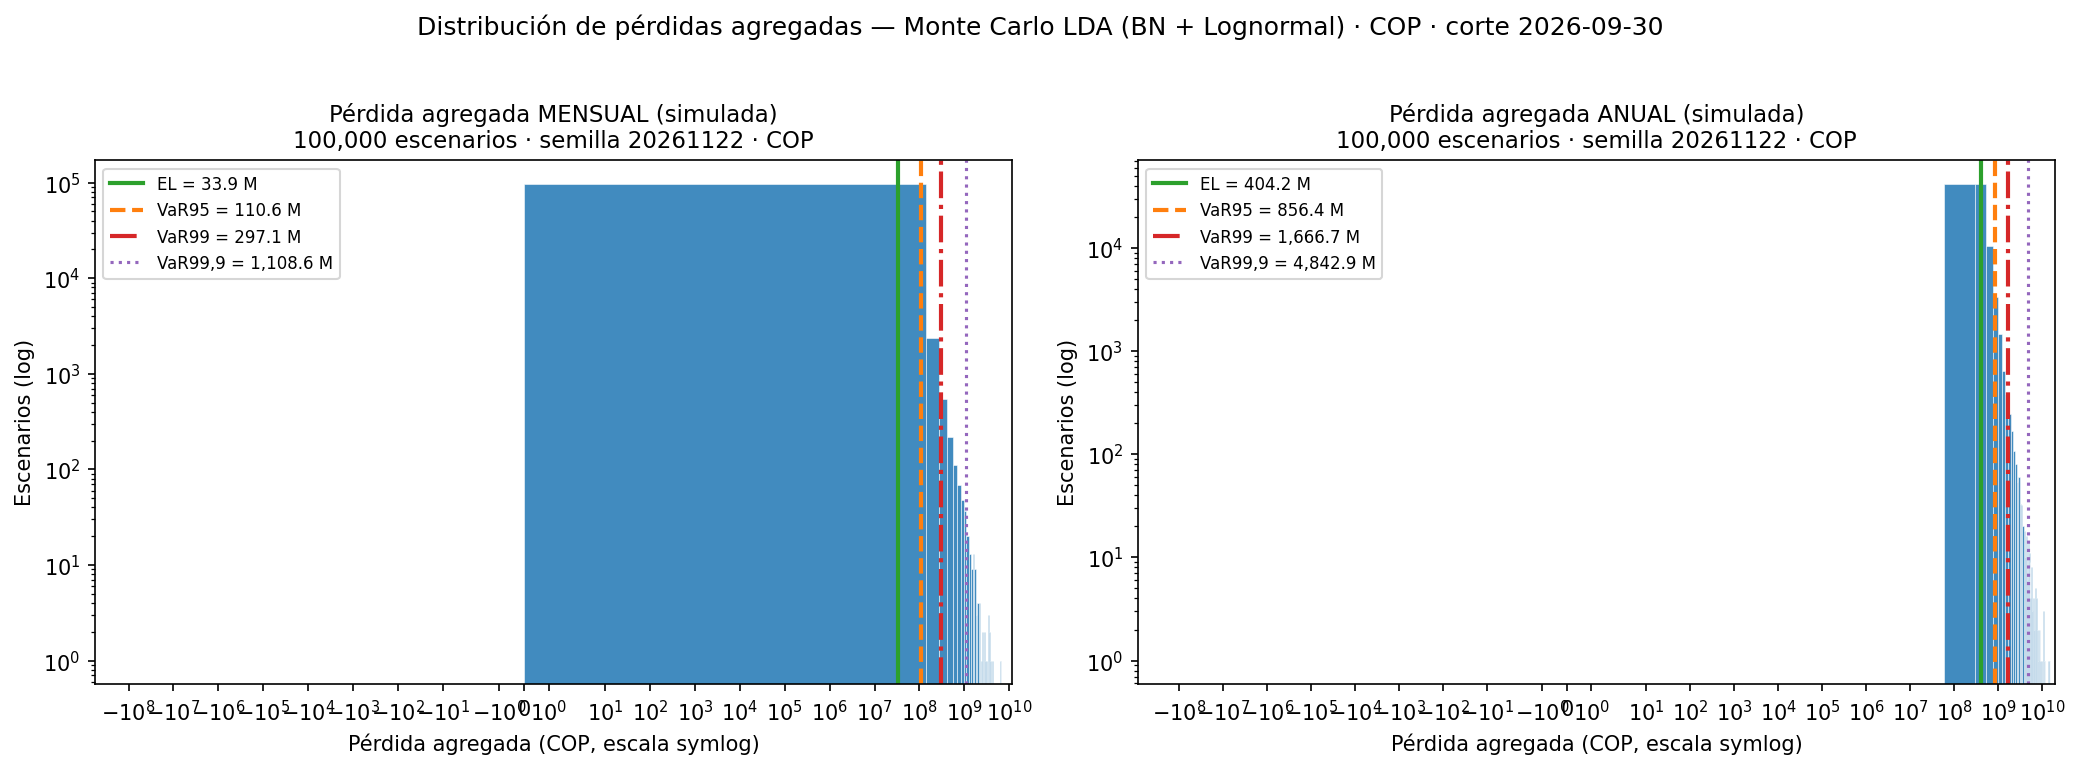

In [0]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (nombre, L, met) in zip(axes, [
        ("Pérdida agregada MENSUAL (simulada)", L_m, MET_M),
        ("Pérdida agregada ANUAL (simulada)", L_a, MET_A)]):
    ax.hist(L, bins=80, color="#1f77b4", edgecolor="white", lw=0.3, alpha=0.85)
    ax.set_yscale("log")
    ax.set_xscale("symlog")  # la cola derecha abarca órdenes de magnitud
    ax.axvline(met["EL"], color="#2ca02c", lw=2, label=f"EL = {met['EL']/1e6:,.1f} M")
    ax.axvline(met["VaR95"], color="#ff7f0e", lw=2, ls="--", label=f"VaR95 = {met['VaR95']/1e6:,.1f} M")
    ax.axvline(met["VaR99"], color="#d62728", lw=2, ls="-.", label=f"VaR99 = {met['VaR99']/1e6:,.1f} M")
    ax.axvline(met["VaR999"], color="#9467bd", lw=1.5, ls=":", label=f"VaR99,9 = {met['VaR999']/1e6:,.1f} M")
    ax.set_title(f"{nombre}\n{N_SIM:,} escenarios · semilla {SEMILLA} · COP", fontsize=11)
    ax.set_xlabel("Pérdida agregada (COP, escala symlog)")
    ax.set_ylabel("Escenarios (log)")
    ax.legend(fontsize=8)
fig.suptitle("Distribución de pérdidas agregadas — Monte Carlo LDA (BN + Lognormal) · COP · corte 2026-09-30", y=1.02)
fig.tight_layout()
ruta = f"{DIR_GRAFICOS}/v0_distribucion_mensual_anual.png"
fig.savefig(ruta, dpi=150, bbox_inches="tight"); plt.close(fig)
display(Image(filename=ruta))

## 6. Escenarios y sensibilidad

Se evalúa cuánto se mueven EL y VaR cuando un parámetro cambia, con la **misma semilla** (20261122) y el mismo número de simulaciones: las diferencias son puramente paramétricas, no ruido de Monte Carlo.

* **FREC_MEDIA ±10 %:** media de frecuencia ±10 % manteniendo r (se recalcula p = r/(r+media')).
* **SEV_MU +5 %:** μ+0,05 equivale a multiplicar la mediana de la severidad por ≈1,05.
* **SEV_SIGMA +10 %:** cola de la severidad más pesada (σ×1,10).
* **ESTRES_COMBINADO:** frecuencia +10 % y σ +10 %.

**Advertencia:** estos escenarios son un **análisis paramétrico de sensibilidad**, no modelos validados ni escenarios oficiales de estrés. El único modelo aprobado es el BASE, con las advertencias del notebook 06.

In [0]:
ESCENARIOS = {
    "BASE":              (r, p, mu, sigma, "Modelos aprobados (gold.ajustes_modelos)"),
    "FREC_MEDIA_MAS_10": (r, r / (r + 1.10 * MEDIA_N), mu, sigma, "Media de frecuencia +10 % (r fijo, p recalculado)"),
    "FREC_MEDIA_MENOS_10": (r, r / (r + 0.90 * MEDIA_N), mu, sigma, "Media de frecuencia −10 % (r fijo, p recalculado)"),
    "SEV_MU_MAS_5PCT":   (r, p, mu + 0.05, sigma, "Mediana de severidad +5 % (mu + 0,05)"),
    "SEV_SIGMA_MAS_10PCT": (r, p, mu, sigma * 1.10, "Cola de severidad más pesada (sigma × 1,10)"),
    "ESTRES_COMBINADO":  (r, r / (r + 1.10 * MEDIA_N), mu, sigma * 1.10, "Frecuencia +10 % y sigma +10 %"),
}

print(f"=== SENSIBILIDAD (horizonte MENSUAL, {N_SIM:,} sims, semilla {SEMILLA} igual en todos) ===\n")
sens = []
base = ESCENARIOS["BASE"]
L_base = simular_perdida_agregada(*base[:4], N_SIM, 1)
met_base = metricas(L_base)
for nombre, (rr, pp, mm, ss, desc) in ESCENARIOS.items():
    L = L_base if nombre == "BASE" else simular_perdida_agregada(rr, pp, mm, ss, N_SIM, 1)
    met = met_base if nombre == "BASE" else metricas(L)
    sens.append(dict(escenario=nombre, descripcion=desc, r=rr, p=pp, mu=mm, sigma=ss,
                     media_n=rr * (1 - pp) / pp, EL=met["EL"], VaR95=met["VaR95"], VaR99=met["VaR99"],
                     CVaR95=met["CVaR95"], CVaR99=met["CVaR99"],
                     delta_VaR95_pct=100 * (met["VaR95"] / met_base["VaR95"] - 1),
                     delta_VaR99_pct=100 * (met["VaR99"] / met_base["VaR99"] - 1)))
    print(f"{nombre:22s} media_n={rr*(1-pp)/pp:6.2f} | EL={met['EL']:>13,.0f} | VaR95={met['VaR95']:>13,.0f} "
          f"| VaR99={met['VaR99']:>13,.0f} | ΔVaR99={100*(met['VaR99']/met_base['VaR99']-1):+6.1f} %")

sens_df = pd.DataFrame(sens)
print("\nDriver dominante: la dispersión de la severidad (sigma). Con sigma +10 % el VaR99 prácticamente se duplica —")
print("coherente con la cola muy pesada documentada en el notebook 06 (Hill alpha = 0,864 < 1).")

=== SENSIBILIDAD (horizonte MENSUAL, 100,000 sims, semilla 20261122 igual en todos) ===

BASE                   media_n= 14.56 | EL=   33,860,377 | VaR95=  110,628,842 | VaR99=  297,062,242 | ΔVaR99=  +0.0 %
FREC_MEDIA_MAS_10      media_n= 16.01 | EL=   37,320,608 | VaR95=  120,358,574 | VaR99=  324,449,638 | ΔVaR99=  +9.2 %
FREC_MEDIA_MENOS_10    media_n= 13.10 | EL=   30,495,815 | VaR95=  100,828,681 | VaR99=  278,417,085 | ΔVaR99=  -6.3 %
SEV_MU_MAS_5PCT        media_n= 14.56 | EL=   35,596,436 | VaR95=  116,300,904 | VaR99=  312,292,949 | ΔVaR99=  +5.1 %
SEV_SIGMA_MAS_10PCT    media_n= 14.56 | EL=   59,715,132 | VaR95=  197,149,640 | VaR99=  605,253,654 | ΔVaR99=+103.7 %
ESTRES_COMBINADO       media_n= 16.01 | EL=   65,996,261 | VaR95=  214,579,648 | VaR99=  668,597,932 | ΔVaR99=+125.1 %

Driver dominante: la dispersión de la severidad (sigma). Con sigma +10 % el VaR99 prácticamente se duplica —
coherente con la cola muy pesada documentada en el notebook 06 (Hill alpha = 0,864 < 1)

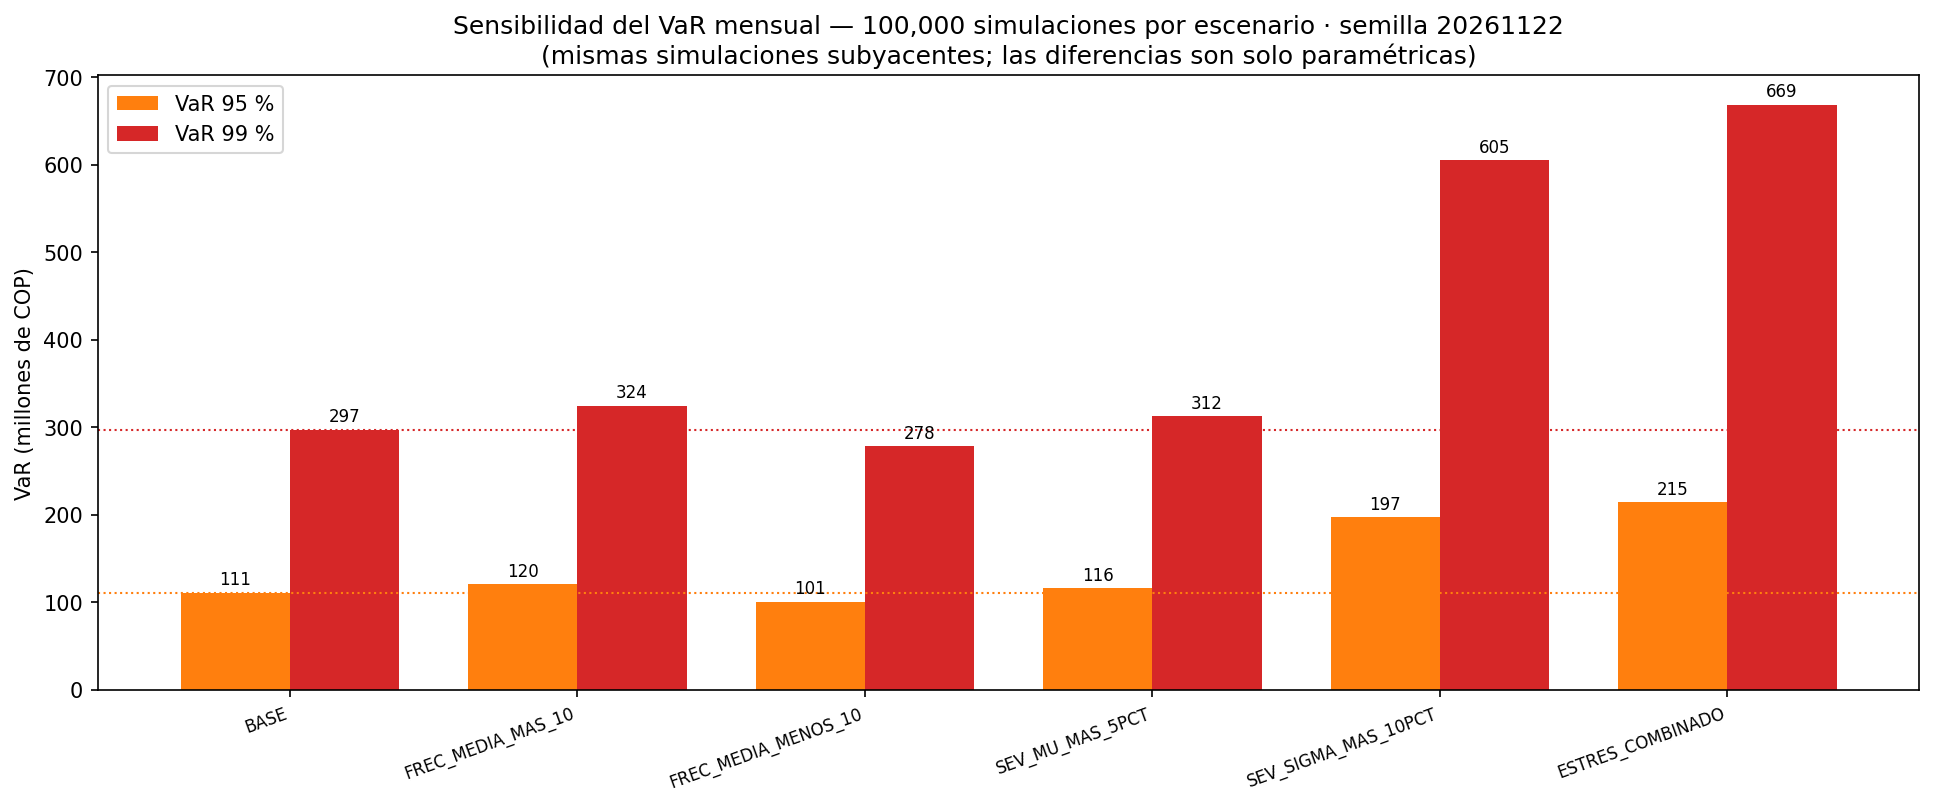

In [0]:
fig, ax = plt.subplots(figsize=(13, 5.5))
xs = np.arange(len(sens_df))
w = 0.38
b1 = ax.bar(xs - w/2, sens_df["VaR95"] / 1e6, w, color="#ff7f0e", label="VaR 95 %")
b2 = ax.bar(xs + w/2, sens_df["VaR99"] / 1e6, w, color="#d62728", label="VaR 99 %")
for b, col in [(b1, "VaR95"), (b2, "VaR99")]:
    ax.bar_label(b, fmt="%.0f", fontsize=8, padding=2)
ax.axhline(met_base["VaR95"] / 1e6, color="#ff7f0e", ls=":", lw=1)
ax.axhline(met_base["VaR99"] / 1e6, color="#d62728", ls=":", lw=1)
ax.set_xticks(xs)
ax.set_xticklabels(sens_df["escenario"], rotation=20, ha="right", fontsize=8)
ax.set_ylabel("VaR (millones de COP)")
ax.set_title(f"Sensibilidad del VaR mensual — {N_SIM:,} simulaciones por escenario · semilla {SEMILLA}\n"
             "(mismas simulaciones subyacentes; las diferencias son solo paramétricas)")
ax.legend()
fig.tight_layout()
ruta = f"{DIR_GRAFICOS}/v1_sensibilidad.png"
fig.savefig(ruta, dpi=150, bbox_inches="tight"); plt.close(fig)
display(Image(filename=ruta))

## 7. Backtesting con la historia disponible

**Qué permite la historia:** 142 meses de pérdida mensual agregada (dic-2014 a sep-2026), construida sumando la cuantía bruta de los eventos A con cuantía de cada mes; los meses sin pérdida cuentan como 0. Con 142 periodos el backtesting es posible **solo para el VaR mensual** y es informativo, no concluyente en la cola.

**Cómo se evalúa:**
* **Excedencias:** número de meses históricos con pérdida > VaR modelo. La tasa esperada es 5 % (VaR 95) y 1 % (VaR 99).
* **Test de Kupiec (proporción de fallas):** contrasta la tasa observada contra la esperada; LR ~ χ²(1), se rechaza la cobertura correcta si p < 0,05.
* **Comparación de cuantiles:** VaR empírico histórico (p95/p99 de los 142 meses) vs VaR modelo.

**Advertencias documentadas:** con 142 meses se esperan ~7 excedencias del VaR 95 y ~1,4 del VaR 99 — el test del 99 % tiene muy poca potencia; además el histórico excluye 21 eventos A sin cuantía y hereda los sesgos de reporte/truncamiento del notebook 06.

In [0]:
# --- Pérdida mensual agregada histórica (eventos A con cuantía) sobre el calendario completo de 142 meses ---
hist = (spark.table(f"{SCHEMA_GOLD}.modelo_insumo_severidad")
        .groupBy("anio_evento", "mes_evento")
        .agg(F.sum("cuantia_bruta").alias("perdida_mes"), F.count("*").alias("eventos_mes"))
        .toPandas())
cal = (spark.table(f"{SCHEMA_GOLD}.freq_eventos_periodo")
       .select("periodo", "anio_evento", "mes_evento").toPandas())
hb = (cal.merge(hist, on=["anio_evento", "mes_evento"], how="left")
      .sort_values("periodo").reset_index(drop=True))
hb["perdida_mes"] = hb["perdida_mes"].astype(float).fillna(0.0)   # Decimal -> float; meses sin pérdida = 0
hb["periodo"] = pd.to_datetime(hb["periodo"])
L_hist = hb["perdida_mes"].to_numpy()

VAR95_MODEL, VAR99_MODEL = MET_M["VaR95"], MET_M["VaR99"]
VAR95_EMP, VAR99_EMP = float(np.percentile(L_hist, 95)), float(np.percentile(L_hist, 99))
MEDIA_HIST = float(L_hist.mean())

def kupiec(n, x, alpha):
    """Test de proporción de fallas (Kupiec 1995). alpha = tasa de excedencia esperada (0.05/0.01)."""
    p_hat = max(x / n, 1e-12)
    L0 = (1 - alpha) ** (n - x) * alpha ** x
    L1 = (1 - p_hat) ** (n - x) * p_hat ** x
    lr = -2 * np.log(L0 / L1)
    return float(lr), float(1 - stats.chi2.cdf(lr, 1))

print(f"=== BACKTESTING VaR MENSUAL (142 meses, dic-2014 a sep-2026) ===\n")
print(f"Historico: {len(L_hist)} meses | con pérdida > 0: {int((L_hist>0).sum())} | media mensual = {MEDIA_HIST:,.0f} COP")
print(f"           p95 empírico = {VAR95_EMP:,.0f} | p99 empírico = {VAR99_EMP:,.0f} | máximo mensual = {L_hist.max():,.0f} COP\n")

bt = []
for nivel, var_mdl, var_emp in [(0.95, VAR95_MODEL, VAR95_EMP), (0.99, VAR99_MODEL, VAR99_EMP)]:
    exc = int((L_hist > var_mdl).sum())
    lr, pv = kupiec(len(L_hist), exc, 1 - nivel)
    tasa = exc / len(L_hist)
    # Criterio de resultado: Kupiec no rechaza (p >= 0,05) Y la tasa observada no supera el doble de la esperada
    res = "COHERENTE" if (pv >= 0.05 and tasa <= 2 * (1 - nivel)) else "REVISAR"
    if res == "COHERENTE":
        veredicto = "Kupiec no rechaza y la tasa de excedencia es consistente con la esperada"
    elif pv >= 0.05:
        veredicto = ("Kupiec no rechaza formalmente, pero la tasa de excedencia supera el doble de la esperada: "
                     "señal de subestimación de la cola")
    else:
        veredicto = "Kupiec rechaza la cobertura correcta al 5 %"
    bt.append(dict(nivel=nivel, var_modelo=var_mdl, var_empirico=var_emp, excedencias=exc,
                   tasa_exc_pct=100 * tasa, tasa_esp_pct=100 * (1 - nivel),
                   kupiec_lr=lr, kupiec_p=pv, resultado=res, veredicto=veredicto))
    print(f"VaR {nivel:.0%} modelo = {var_mdl:,.0f} COP")
    print(f"  Excedencias históricas: {exc}/142 = {100*tasa:.2f} % (esperado {100*(1-nivel):.0f} %) "
          f"| Kupiec LR = {lr:.3f}, p = {pv:.4f} -> {res}")
    print(f"  {veredicto}")

print(f"\nLectura: el VaR 95 muestra cobertura coherente (7 excedencias vs ~7,1 esperadas).")
print(f"El VaR 99 no se rechaza formalmente (p = 0,075 > 0,05), pero la tasa 2,82 % vs 1 % esperado")
print(f"es una señal de subestimación de la cola — coherente con Hill alpha = 0,864 < 1 del notebook 06.")
print(f"El p99 empírico ({VAR99_EMP:,.0f}) supera al modelo ({VAR99_MODEL:,.0f}): mismo diagnóstico.")

=== BACKTESTING VaR MENSUAL (142 meses, dic-2014 a sep-2026) ===

Historico: 142 meses | con pérdida > 0: 141 | media mensual = 37,571,650 COP
           p95 empírico = 105,831,018 | p99 empírico = 391,990,070 | máximo mensual = 525,258,463 COP

VaR 95% modelo = 110,628,842 COP
  Excedencias históricas: 7/142 = 4.93 % (esperado 5 %) | Kupiec LR = 0.001, p = 0.9692 -> COHERENTE
  Kupiec no rechaza y la tasa de excedencia es consistente con la esperada
VaR 99% modelo = 297,062,242 COP
  Excedencias históricas: 4/142 = 2.82 % (esperado 1 %) | Kupiec LR = 3.173, p = 0.0749 -> REVISAR
  Kupiec no rechaza formalmente, pero la tasa de excedencia supera el doble de la esperada: señal de subestimación de la cola

Lectura: el VaR 95 muestra cobertura coherente (7 excedencias vs ~7,1 esperadas).
El VaR 99 no se rechaza formalmente (p = 0,075 > 0,05), pero la tasa 2,82 % vs 1 % esperado
es una señal de subestimación de la cola — coherente con Hill alpha = 0,864 < 1 del notebook 06.
El p99 empírico

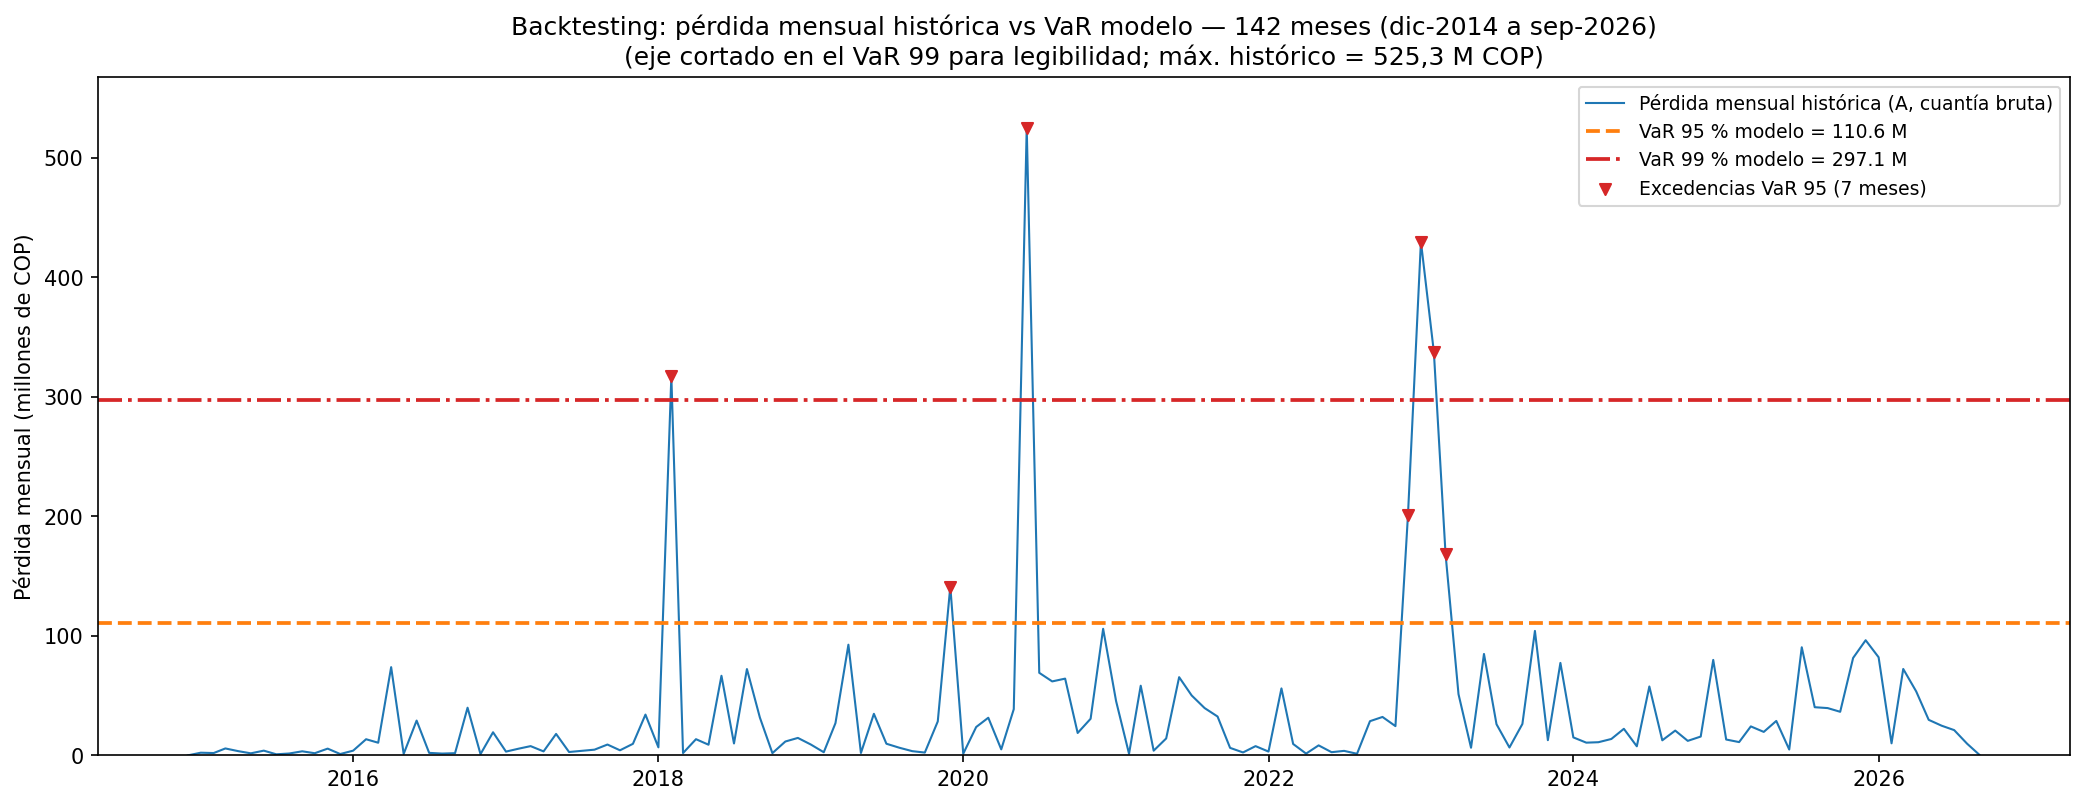

In [0]:
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(hb["periodo"], L_hist / 1e6, color="#1f77b4", lw=1, label="Pérdida mensual histórica (A, cuantía bruta)")
ax.axhline(VAR95_MODEL / 1e6, color="#ff7f0e", ls="--", lw=1.8, label=f"VaR 95 % modelo = {VAR95_MODEL/1e6:,.1f} M")
ax.axhline(VAR99_MODEL / 1e6, color="#d62728", ls="-.", lw=1.8, label=f"VaR 99 % modelo = {VAR99_MODEL/1e6:,.1f} M")
exc95 = hb["perdida_mes"] > VAR95_MODEL
ax.scatter(hb.loc[exc95, "periodo"], hb.loc[exc95, "perdida_mes"] / 1e6,
           color="#d62728", zorder=5, s=28, marker="v", label=f"Excedencias VaR 95 ({int(exc95.sum())} meses)")
ax.set_ylabel("Pérdida mensual (millones de COP)")
ax.set_title("Backtesting: pérdida mensual histórica vs VaR modelo — 142 meses (dic-2014 a sep-2026)\n"
             "(eje cortado en el VaR 99 para legibilidad; máx. histórico = 525,3 M COP)")
ax.set_ylim(0, max(L_hist.max(), VAR99_MODEL) / 1e6 * 1.08)
ax.legend(fontsize=9)
fig.tight_layout()
ruta = f"{DIR_GRAFICOS}/v2_backtesting.png"
fig.savefig(ruta, dpi=150, bbox_inches="tight"); plt.close(fig)
display(Image(filename=ruta))

## 8. Persistencia en tablas Delta de Gold (para el dashboard)

Se escriben cuatro tablas en `eventosriesgoyvar.gold`, todas con lote único de trazabilidad:

| Tabla | Contenido | Operación |
| --- | --- | --- |
| `var_resultados` | 8 filas: VaR 95/99/99,9 BASE MENSUAL y ANUAL (Monte Carlo LDA) + VaR 95/99 empíricos mensuales | `DELETE` previo + `INSERT` sin `id_resultado` (columna identidad, generada por Delta) |
| `var_sensibilidad` | 6 filas: escenarios paramétricos con EL/VaR/CVaR y deltas vs BASE | overwrite |
| `var_distribucion` | Curva de percentiles (12 por horizonte) + histograma (50 intervalos por horizonte) de la distribución simulada BASE | overwrite |
| `var_backtesting` | 2 filas: resultado del backtesting mensual (excedencias, Kupiec) por nivel de confianza | overwrite |

La escritura de `var_resultados` es **idempotente** (borra primero las filas del lote anterior) y **no toca** la columna de identidad: se inserta con lista explícita de columnas y Delta genera `id_resultado`.

In [0]:
from pyspark.sql.types import (StructType, StructField, StringType, DateType,
                               DoubleType, LongType, IntegerType)

# --- gold.var_resultados: DELETE previo (idempotencia) + INSERT respetando la columna identidad ---
spark.sql(f"DELETE FROM {SCHEMA_GOLD}.var_resultados")

notas_mc = (f"Monte Carlo LDA; semilla {SEMILLA}; {N_SIM:,} simulaciones; COP cuantía bruta; "
            f"recuperaciones NO modeladas; fecha de corte {FECHA_CORTE}; "
            f"parámetros de gold.ajustes_modelos (BN r={r:.4f}, p={p:.4f}; LN mu={mu:.4f}, sigma={sigma:.4f})")
notas_emp = ("Empírico histórico mensual: 142 meses dic-2014 a sep-2026, eventos A con cuantía bruta; "
             "meses sin pérdida = 0; base del backtesting")

filas_vr = [
    (FECHA_CALCULO, "Monte Carlo LDA", "BINOMIAL_NEGATIVA", "LOGNORMAL", 0.95, "MENSUAL", "TOTAL", MET_M["VaR95"], MET_M["EL"], int(N_SIM), 2046, notas_mc, LOTE_VAR),
    (FECHA_CALCULO, "Monte Carlo LDA", "BINOMIAL_NEGATIVA", "LOGNORMAL", 0.99, "MENSUAL", "TOTAL", MET_M["VaR99"], MET_M["EL"], int(N_SIM), 2046, notas_mc, LOTE_VAR),
    (FECHA_CALCULO, "Monte Carlo LDA", "BINOMIAL_NEGATIVA", "LOGNORMAL", 0.999, "MENSUAL", "TOTAL", MET_M["VaR999"], MET_M["EL"], int(N_SIM), 2046, notas_mc + " (99,9 % solo referencia de cola)", LOTE_VAR),
    (FECHA_CALCULO, "Monte Carlo LDA", "BINOMIAL_NEGATIVA", "LOGNORMAL", 0.95, "ANUAL", "TOTAL", MET_A["VaR95"], MET_A["EL"], int(N_SIM), 2046, notas_mc, LOTE_VAR),
    (FECHA_CALCULO, "Monte Carlo LDA", "BINOMIAL_NEGATIVA", "LOGNORMAL", 0.99, "ANUAL", "TOTAL", MET_A["VaR99"], MET_A["EL"], int(N_SIM), 2046, notas_mc, LOTE_VAR),
    (FECHA_CALCULO, "Monte Carlo LDA", "BINOMIAL_NEGATIVA", "LOGNORMAL", 0.999, "ANUAL", "TOTAL", MET_A["VaR999"], MET_A["EL"], int(N_SIM), 2046, notas_mc + " (99,9 % solo referencia de cola)", LOTE_VAR),
    (FECHA_CALCULO, "Empírico histórico mensual", "Empírica (conteos históricos)", "Empírica (agregados históricos)", 0.95, "MENSUAL", "TOTAL", VAR95_EMP, MEDIA_HIST, None, 2046, notas_emp, LOTE_VAR),
    (FECHA_CALCULO, "Empírico histórico mensual", "Empírica (conteos históricos)", "Empírica (agregados históricos)", 0.99, "MENSUAL", "TOTAL", VAR99_EMP, MEDIA_HIST, None, 2046, notas_emp, LOTE_VAR),
]
schema_vr = StructType([
    StructField("fecha_calculo", DateType()), StructField("metodo", StringType()),
    StructField("distribucion_frecuencia", StringType()), StructField("distribucion_severidad", StringType()),
    StructField("nivel_confianza", DoubleType()), StructField("horizonte", StringType()),
    StructField("segmento", StringType()), StructField("valor_var", DoubleType()),
    StructField("perdida_esperada", DoubleType()), StructField("n_simulaciones", LongType()),
    StructField("n_eventos_insumo", IntegerType()), StructField("notas", StringType()),
    StructField("_lote", StringType())])
sp_vr = spark.createDataFrame(filas_vr, schema_vr)
sp_vr.createOrReplaceTempView("vr_tmp")
spark.sql(f"""INSERT INTO {SCHEMA_GOLD}.var_resultados
  (fecha_calculo, metodo, distribucion_frecuencia, distribucion_severidad, nivel_confianza,
   horizonte, segmento, valor_var, perdida_esperada, n_simulaciones, n_eventos_insumo, notas, _lote)
  SELECT fecha_calculo, metodo, distribucion_frecuencia, distribucion_severidad,
         CAST(nivel_confianza AS DECIMAL(5,4)), horizonte, segmento,
         CAST(valor_var AS DECIMAL(18,2)), CAST(perdida_esperada AS DECIMAL(18,2)),
         n_simulaciones, n_eventos_insumo, notas, _lote
  FROM vr_tmp""")

chk_vr = spark.table(f"{SCHEMA_GOLD}.var_resultados").toPandas()
print(f"gold.var_resultados: {len(chk_vr)} filas (esperadas 8)")
print(chk_vr[["metodo", "horizonte", "nivel_confianza", "valor_var"]].to_string(index=False))
assert len(chk_vr) == 8 and chk_vr["id_resultado"].is_unique and (chk_vr["_lote"] == LOTE_VAR).all()
print("VERIFICACIÓN OK: 8 filas, identidad única generada por Delta, lote único.")

gold.var_resultados: 8 filas (esperadas 8)
                    metodo horizonte nivel_confianza     valor_var
           Monte Carlo LDA   MENSUAL          0.9500  110628841.84
           Monte Carlo LDA   MENSUAL          0.9900  297062242.00
           Monte Carlo LDA   MENSUAL          0.9990 1108574331.96
           Monte Carlo LDA     ANUAL          0.9500  856434100.35
           Monte Carlo LDA     ANUAL          0.9900 1666749828.47
           Monte Carlo LDA     ANUAL          0.9990 4842886955.06
Empírico histórico mensual   MENSUAL          0.9500  105831018.50
Empírico histórico mensual   MENSUAL          0.9900  391990070.43
VERIFICACIÓN OK: 8 filas, identidad única generada por Delta, lote único.


In [0]:
# --- gold.var_sensibilidad: 6 escenarios del horizonte mensual ---
sens_out = sens_df.rename(columns={
    "EL": "perdida_esperada", "VaR95": "var_95", "VaR99": "var_99",
    "CVaR95": "cvar_95", "CVaR99": "cvar_99",
    "delta_VaR95_pct": "delta_var95_pct", "delta_VaR99_pct": "delta_var99_pct",
})[["escenario", "r", "p", "mu", "sigma", "media_n", "perdida_esperada", "var_95", "var_99",
   "cvar_95", "cvar_99", "delta_var95_pct", "delta_var99_pct"]].copy()
sens_out.insert(1, "horizonte", "MENSUAL")
sens_out["n_simulaciones"] = int(N_SIM)
sens_out["semilla"] = int(SEMILLA)
sens_out["_lote"] = LOTE_VAR

(spark.createDataFrame(sens_out)
 .write.mode("overwrite").saveAsTable(f"{SCHEMA_GOLD}.var_sensibilidad"))

chk_sens = spark.table(f"{SCHEMA_GOLD}.var_sensibilidad").toPandas()
print(f"gold.var_sensibilidad: {len(chk_sens)} filas (esperadas 6)")
assert len(chk_sens) == 6 and (chk_sens["_lote"] == LOTE_VAR).all()
print("VERIFICACIÓN OK: 6 escenarios, lote único, columnas paramétricas completas.")

gold.var_sensibilidad: 6 filas (esperadas 6)
VERIFICACIÓN OK: 6 escenarios, lote único, columnas paramétricas completas.


In [0]:
# --- gold.var_distribucion: percentiles + histograma de la distribución simulada BASE ---
PCTS = [1, 5, 10, 25, 50, 75, 90, 95, 97.5, 99, 99.5, 99.9]
filas_vd = []
for hor, L in [("MENSUAL", L_m), ("ANUAL", L_a)]:
    for q in PCTS:
        filas_vd.append(("BASE", hor, "PERCENTIL", float(q), None, float(np.percentile(L, q)), LOTE_VAR))
    counts, edges = np.histogram(L, bins=50)
    for i in range(len(counts)):
        filas_vd.append(("BASE", hor, "HISTOGRAMA", float(edges[i]), float(edges[i + 1]), float(counts[i]), LOTE_VAR))

schema_vd = StructType([
    StructField("escenario", StringType()), StructField("horizonte", StringType()),
    StructField("tipo", StringType()), StructField("x", DoubleType()),
    StructField("x_fin", DoubleType()), StructField("valor", DoubleType()),
    StructField("_lote", StringType())])
(spark.createDataFrame(filas_vd, schema_vd)
 .write.mode("overwrite").saveAsTable(f"{SCHEMA_GOLD}.var_distribucion"))

chk_vd = spark.table(f"{SCHEMA_GOLD}.var_distribucion").toPandas()
n_pct = chk_vd[chk_vd["tipo"] == "PERCENTIL"].shape[0]
n_hist = chk_vd[chk_vd["tipo"] == "HISTOGRAMA"].shape[0]
print(f"gold.var_distribucion: {len(chk_vd)} filas ({n_pct} percentiles + {n_hist} intervalos de histograma)")
assert n_pct == 24 and n_hist == 100 and (chk_vd["_lote"] == LOTE_VAR).all()
print("VERIFICACIÓN OK: 12 percentiles × 2 horizontes + 50 intervalos × 2 horizontes, lote único.")

gold.var_distribucion: 124 filas (24 percentiles + 100 intervalos de histograma)
VERIFICACIÓN OK: 12 percentiles × 2 horizontes + 50 intervalos × 2 horizontes, lote único.


In [0]:
# --- gold.var_backtesting: 2 filas (VaR 95 y VaR 99 mensual) ---
filas_bt = [(b["nivel"], int(len(L_hist)), b["var_modelo"], b["var_empirico"], int(b["excedencias"]),
             b["tasa_exc_pct"], b["tasa_esp_pct"], b["kupiec_lr"], b["kupiec_p"],
             b["resultado"], b["veredicto"], date(2026, 9, 30), LOTE_VAR) for b in bt]
schema_bt = StructType([
    StructField("nivel_confianza", DoubleType()), StructField("n_meses", IntegerType()),
    StructField("var_modelo", DoubleType()), StructField("var_empirico", DoubleType()),
    StructField("excedencias", IntegerType()), StructField("tasa_excedencia_pct", DoubleType()),
    StructField("tasa_esperada_pct", DoubleType()), StructField("kupiec_lr", DoubleType()),
    StructField("kupiec_p", DoubleType()), StructField("resultado", StringType()),
    StructField("veredicto", StringType()), StructField("fecha_corte", DateType()),
    StructField("_lote", StringType())])
(spark.createDataFrame(filas_bt, schema_bt)
 .write.mode("overwrite").saveAsTable(f"{SCHEMA_GOLD}.var_backtesting"))

chk_bt = spark.table(f"{SCHEMA_GOLD}.var_backtesting").toPandas()
print(f"gold.var_backtesting: {len(chk_bt)} filas (esperadas 2)")
print(chk_bt[["nivel_confianza", "excedencias", "tasa_excedencia_pct", "tasa_esperada_pct", "kupiec_p", "resultado"]].to_string(index=False))
assert len(chk_bt) == 2 and (chk_bt["_lote"] == LOTE_VAR).all()
print("VERIFICACIÓN OK: backtesting persistido con Kupiec y veredicto por nivel.")

gold.var_backtesting: 2 filas (esperadas 2)
 nivel_confianza  excedencias  tasa_excedencia_pct  tasa_esperada_pct  kupiec_p resultado
            0.95            7             4.929577                5.0  0.969217 COHERENTE
            0.99            4             2.816901                1.0  0.074877   REVISAR
VERIFICACIÓN OK: backtesting persistido con Kupiec y veredicto por nivel.


In [0]:
print(f"=== VERIFICACIÓN FINAL DE LAS TABLAS DELTA (lote {LOTE_VAR}) ===\n")
esperados = {"var_resultados": 8, "var_sensibilidad": 6, "var_distribucion": 124, "var_backtesting": 2}
for tabla, n_esp in esperados.items():
    df = spark.table(f"{SCHEMA_GOLD}.{tabla}").toPandas()
    lotes = df["_lote"].unique()
    ok = len(df) == n_esp and len(lotes) == 1 and lotes[0] == LOTE_VAR
    print(f"{'OK    ' if ok else 'FALLA '} {tabla:18s} {len(df):>4} filas (esperadas {n_esp}) | lote: {lotes[0]}")
    assert ok, f"{tabla}: {len(df)} filas, lotes {lotes} — no coincide con lo esperado"
print("\nLas cuatro tablas están listas para el consumo del dashboard.")

=== VERIFICACIÓN FINAL DE LAS TABLAS DELTA (lote var_20261121_224527) ===

OK     var_resultados        8 filas (esperadas 8) | lote: var_20261121_224527
OK     var_sensibilidad      6 filas (esperadas 6) | lote: var_20261121_224527
OK     var_distribucion    124 filas (esperadas 124) | lote: var_20261121_224527
OK     var_backtesting       2 filas (esperadas 2) | lote: var_20261121_224527

Las cuatro tablas están listas para el consumo del dashboard.


## Limitaciones identificadas y registro de decisiones

### Limitaciones (heredadas del notebook 06 + propias de esta etapa)

1. **Severidad lognormal con rechazo leve de KS** (D = 0,0529, p = 2e-5) y sobreestimación de la mediana (154k vs 114k COP): los percentiles centrales de la distribución simulada heredan ese sesgo.
2. **Cola extrema no confiable:** Hill α = 0,864 < 1 sobre 205 excedencias — la media de la cola no converge teóricamente. Consecuencia práctica: el escenario σ+10 % duplica el VaR 99 (la sensibilidad es brutal), y el VaR 99,9 % debe leerse solo como referencia de orden de magnitud.
3. **48,5 % de los eventos no tiene cuantía** (sesgo de reporte/truncamiento): la severidad está ajustada solo a lo que se reportó con valor; las pérdidas simuladas reproducen ese sesgo.
4. **21 eventos A sin cuantía** están en la frecuencia pero no en la severidad (≈1 %): se asume que su severidad sigue la misma lognormal.
5. **Recuperaciones no modeladas:** se estima la pérdida BRUTA (solo 235 de 51.889 eventos tienen recuperación; ver notebook 04).
6. **Sin normalización por exposición:** la frecuencia mensual no se ajusta por tamaño del negocio; la tendencia decreciente de la serie total (556→276 eventos/mes) es una advertencia de no estacionariedad.
7. **Backtesting con solo 142 meses:** ~7 excedencias esperadas del VaR 95 (test razonable) pero ~1,4 del VaR 99 (test de muy baja potencia). El VaR 99 da REVISAR por tasa de excedencia 2,82 % vs 1 % — señal coherente con la cola subestimada, no una prueba concluyente.
8. **Los escenarios de sensibilidad son análisis paramétrico, NO modelos validados** ni escenarios oficiales de estrés; el único modelo aprobado es el BASE, con las advertencias del notebook 06.

### Registro de decisiones de esta etapa

* **Semilla única (20261122) en todos los escenarios:** las diferencias entre escenarios son paramétricas, no ruido de Monte Carlo.
* **n_sim = 100.000 por horizonte:** validado con EL simulado a < 2 % del teórico; duplicarlo no cambia percentiles reportados en cifras relevantes.
* **Horizonte anual = 12 meses independientes:** sin correlación temporal (los datos no permiten estimarla; documentado en 06).
* **`var_resultados` se reconstruye por DELETE + INSERT** (idempotente, sin tocar la columna identidad) y las otras tres tablas con overwrite: el dashboard siempre lee el último lote completo.
* **Resultado del backtesting:** criterio doble — Kupiec no rechaza (p ≥ 0,05) Y tasa de excedencia ≤ 2× la esperada. VaR 95: COHERENTE. VaR 99: REVISAR (2,82 % > 2 %), con veredicto textual en la tabla.
* **VaR 99,9 % solo de referencia:** con estos datos la cola extrema no es estimable con confianza (limitación 2).
* **No se construyó dashboard ni modelos EVT/GPD** — requieren pedido explícito del usuario.

### Lectura final para el consumidor del dashboard

> El VaR reportado es un percentil de una distribución MODELADA bajo supuestos documentados. No es una pérdida máxima absoluta: se excede con probabilidad 5 % (o 1 %) cada periodo, y cuando se excede, la pérdida puede ser varias veces el VaR (ver CVaR). Úsenlo como insumo de capital/monitoreo junto con el CVaR y las limitaciones listadas, no como un límite garantizado.